# Trabalho Prático: Tomada de Decisão em Limpeza de Dados

**Dataset:** [Ames Housing Dataset](https://www.kaggle.com/datasets/prevek18/ames-housing-dataset)

**Objetivo:** Este trabalho desafia você a atuar como um cientista de dados responsável por preparar um dataset bruto para modelagem. Em vez de seguir instruções, sua tarefa é analisar, tomar decisões informadas e justificar cada passo do processo de limpeza e transformação. O objetivo final é produzir um DataFrame limpo e robusto, pronto para ser usado em um modelo de machine learning para prever o preço de venda das casas.

**Data dictionary usado:** https://hackmd.io/@jirvingphd/ames-data-dictionary

**Nome**: Mikaelle Costa de Santana

---

### Seção 0: Configuração Inicial

**Enunciado:** Importe as bibliotecas necessárias (pandas, numpy, matplotlib, seaborn) e carregue o dataset `AmesHousing.csv` em um DataFrame chamado `df`.

In [5]:
# Célula de resposta para a Seção 0

# Importe as bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure o estilo dos gráficos
sns.set_style("whitegrid")

# Carregue o dataset
try:
    df = pd.read_csv('AmesHousing.csv')
    print("Dataset carregado com sucesso!")
except FileNotFoundError:
    print("Arquivo 'AmesHousing.csv' não encontrado. Certifique-se de que ele está no diretório correto.")

Dataset carregado com sucesso!


### Seção 1: Diagnóstico e Formulação de Hipóteses

**Enunciado:** Todo bom projeto de limpeza começa com um diagnóstico completo. Sua primeira tarefa é entender profundamente o estado inicial dos dados.

1.  Execute uma análise de perfilamento básica no dataset. Utilize os métodos que julgar necessários (`.shape`, `.info()`, `.head()`, `.describe()`, etc.) para obter uma visão geral.
2.  **Tomada de Decisão:** Com base na sua análise inicial, formule hipóteses sobre os principais desafios deste dataset em uma célula de Markdown. Quais colunas parecem mais problemáticas? Que tipo de ações você *acha* que precisará tomar? (Ex: "A coluna 'Alley' tem muitos valores ausentes, talvez precise ser removida." ou "A coluna 'SalePrice' parece ter valores muito altos, precisarei investigar outliers.").

In [6]:
# Célula de resposta para a Seção 1

# resumo conciso do DataFrame
print("Informações do DataFrame:")
df.info()

# dimensões do DataFrame (linhas, colunas)
print(f"Dimensões do dataset: {df.shape}")

# nomes das colunas
print(f"Colunas do dataset: {df.columns.tolist()}")

# tipos de dados de cada coluna
print("Tipos de dados (Dtypes):")
print(df.dtypes)

# colunas numéricas
numeric_cols = df.select_dtypes(include=np.number)
print("Colunas numéricas:")
display(numeric_cols.head())

# colunas de objeto (texto)
object_cols = df.select_dtypes(include='object')
print("\nColunas de objeto:")
display(object_cols.head())

# estatísticas descritivas para colunas numéricas
print("Estatísticas descritivas (numéricas):")
display(df.describe())

# estatísticas descritivas para colunas de objeto
print("\nEstatísticas descritivas (categóricas):")
display(df.describe(include=['object']))

# Explore o dataset livremente para fazer seu diagnóstico.


Informações do DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   object 
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   object 
 7   Alley            198 non-null    object 
 8   Lot Shape        2930 non-null   object 
 9   Land Contour     2930 non-null   object 
 10  Utilities        2930 non-null   object 
 11  Lot Config       2930 non-null   object 
 12  Land Slope       2930 non-null   object 
 13  Neighborhood     2930 non-null   object 
 14  Condition 1      2930 non-null   object 
 15  Condition 2      2930 non-null   object 
 16  Bldg Type        2930 non-null   o

,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,1,526301100,20,141.0,31770,6,5,1960,1960,112.0,...,210,62,0,0,0,0,0,5,2010,215000
1,2,526350040,20,80.0,11622,5,6,1961,1961,0.0,...,140,0,0,0,120,0,0,6,2010,105000
2,3,526351010,20,81.0,14267,6,6,1958,1958,108.0,...,393,36,0,0,0,0,12500,6,2010,172000
3,4,526353030,20,93.0,11160,7,5,1968,1968,0.0,...,0,0,0,0,0,0,0,4,2010,244000
4,5,527105010,60,74.0,13830,5,5,1997,1998,0.0,...,212,34,0,0,0,0,0,3,2010,189900



Colunas de objeto:


,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition
0,RL,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,...,Attchd,Fin,TA,TA,P,NaN,NaN,NaN,WD,Normal
1,RH,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,...,Attchd,Unf,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal
2,RL,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,NaN,NaN,Gar2,WD,Normal
3,RL,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,...,Attchd,Fin,TA,TA,Y,NaN,NaN,NaN,WD,Normal
4,RL,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,...,Attchd,Fin,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal


Estatísticas descritivas (numéricas):


,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2930.00000,2.930000e+03,2930.000000,2440.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2907.000000,...,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000
mean,1465.50000,7.144645e+08,57.387372,69.224590,10147.921843,6.094881,5.563140,1971.356314,1984.266553,101.896801,...,93.751877,47.533447,23.011604,2.592491,16.002048,2.243345,50.635154,6.216041,2007.790444,180796.060068
std,845.96247,1.887308e+08,42.638025,23.365335,7880.017759,1.411026,1.111537,30.245361,20.860286,179.112611,...,126.361562,67.483400,64.139059,25.141331,56.087370,35.597181,566.344288,2.714492,1.316613,79886.692357
min,1.00000,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,733.25000,5.284770e+08,20.000000,58.000000,7440.250000,5.000000,5.000000,1954.000000,1965.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,1465.50000,5.354536e+08,50.000000,68.000000,9436.500000,6.000000,5.000000,1973.000000,1993.000000,0.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,2197.75000,9.071811e+08,70.000000,80.000000,11555.250000,7.000000,6.000000,2001.000000,2004.000000,164.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213500.000000
max,2930.00000,1.007100e+09,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,...,1424.000000,742.000000,1012.000000,508.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000,755000.000000



Estatísticas descritivas (categóricas):


,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition
count,2930,2930,198,2930,2930,2930,2930,2930,2930,2930,...,2773,2771,2771,2771,2930,13,572,106,2930,2930
unique,7,2,2,4,4,3,5,3,28,9,...,6,3,5,5,3,4,4,5,10,6
top,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,Ex,MnPrv,Shed,WD,Normal
freq,2273,2918,120,1859,2633,2927,2140,2789,443,2522,...,1731,1231,2615,2665,2652,4,330,95,2536,2413


**Hipóteses e Plano de ação inicial:**

*  Colunas como Pool QC, Misc Feature, Alley e Fence têm mais de 80% de dados ausentes. É provável que precisem ser removidas ou transformadas em variáveis binárias (“tem/não tem”).

* Outras colunas com ausências moderadas (Mas Vnr Area, Garage Yr Blt, Bsmt Qual, etc.) provavelmente exigirão imputação (ex.: preencher com "Nenhum" ou zero, conforme o contexto).

* Possíveis outliers: SalePrice e variáveis contínuas como Lot Area, Gr Liv Area, Total Bsmt SF podem ter valores extremos que distorcem modelos. Vale investigar distribuições para detectar anomalias. -->



### Seção 2: Estratégia para Dados Ausentes (Missing Values)

**Enunciado:** Este dataset tem uma quantidade significativa de dados ausentes. Sua missão é desenvolver e aplicar uma estratégia coesa para lidar com eles.

1.  Calcule e analise a porcentagem de dados ausentes em cada coluna.
2.  **Tomada de Decisão (Remoção):** Com base na análise, proponha uma estratégia para colunas com uma quantidade muito alta de valores ausentes. Devemos remover algumas colunas? Se sim, qual seria um bom limiar (threshold) de porcentagem de ausência para justificar a remoção? Justifique sua decisão e implemente-a.
3.  **Tomada de Decisão (Imputação Categórica):** Consulte o dicionário de dados (`data_description.txt`). O que `NaN` significa para colunas como `Fence` ou `GarageType`? Qual é a melhor estratégia de imputação para estas colunas categóricas, considerando o significado dos dados? Implemente sua estratégia.
4.  **Tomada de Decisão (Imputação Numérica):** Investigue a coluna numérica `LotFrontage`. Analise sua distribuição (usando histograma e `.describe()`). É mais apropriado usar a média, a mediana ou outra estratégia para preencher os valores ausentes? Justifique sua escolha e implemente-a. Faça o mesmo para outras colunas numéricas que ainda possuam valores ausentes.

In [7]:
# Célula de resposta para a Seção 2

# 1. Calcule a porcentagem de valores ausentes

# porcentagem de valores ausentes por coluna
missing_percentage = (df.isnull().sum() / len(df)) * 100
print("\nPorcentagem de valores ausentes por coluna:")
print(missing_percentage[missing_percentage > 0].sort_values(ascending=False))



Porcentagem de valores ausentes por coluna:
Pool QC           99.556314
Misc Feature      96.382253
Alley             93.242321
Fence             80.477816
Mas Vnr Type      60.580205
Fireplace Qu      48.532423
Lot Frontage      16.723549
Garage Qual        5.426621
Garage Cond        5.426621
Garage Yr Blt      5.426621
Garage Finish      5.426621
Garage Type        5.358362
Bsmt Exposure      2.832765
BsmtFin Type 2     2.764505
Bsmt Cond          2.730375
Bsmt Qual          2.730375
BsmtFin Type 1     2.730375
Mas Vnr Area       0.784983
Bsmt Full Bath     0.068259
Bsmt Half Bath     0.068259
BsmtFin SF 1       0.034130
BsmtFin SF 2       0.034130
Electrical         0.034130
Total Bsmt SF      0.034130
Bsmt Unf SF        0.034130
Garage Area        0.034130
Garage Cars        0.034130
dtype: float64


## **Colunas com altíssima taxa de ausência (> 80%)**

Pool QC, Misc Feature, Alley e Fence. Essas variáveis praticamente não têm dados.

Possíveis estratégias: remover, ou transformar em binárias (“tem/não tem”).

## **Colunas com ausência moderada (10% – 50%)**

Fireplace Qu e Lot Frontage.

FireplaceQu pode ser preenchida com “No Fireplace” (NA = ausência de lareira).

LotFrontage pode ser imputada (média por bairro).

## **Colunas com a baixa ausência (1% – 6%)**

Grupo da Garagem (Garage Cond, Garage Finish, Garage YrBlt, Garage Qual, Garage Type), Bsmt Exposure, BsmtFin Type 2, Bsmt Qual, Bsmt Cond, BsmtFin Type 1, Mas Vnr Area e Mas Vnr Type.

Geralmente NA significa “não tem garagem” ou “não tem porão”. Pode ser imputado com essa categoria.

Mas Vnr (masonry veneer) → NA pode significar “None”.

## **Colunas quase completas (< 1%)**

Bsmt Full Bath, Bsmt Half Bath, Electrical, Garage Cars, Garage Area, Total Bsmt SF, Bsmt Unf SF, BsmtFin SF 1/2

Podem ser imputados com moda/mediana.

In [8]:
# 2. Justificativa e implementação da remoção de colunas

# Justificativa
print("""
Minha justificativa é...
Colunas com > 80% de valores ausentes tendem a não agregar informação útil, porque os dados são escassos e podem introduzir mais ruído do que valor.
Se ficarem, seria necessário imputar a maior parte dos registros, o que seria artificial.
Pool QC, Misc Feature, Alley e Fence ultrapassam o threshold de 80%, ou seja, são candidatos fortes à remoção.

= Justificativa de remoção =

Pouca representatividade: quase todos os registros são NA.
Difícil imputação confiável: mesmo se preenchermos, o dado imputado teria pouco suporte real.
Risco de viés: usar essas colunas pode distorcer o modelo (muito mais “NA” do que categorias reais).
Ganhos de simplicidade: descartando, reduzimos dimensionalidade sem perda significativa de informação.
""")

# Implementação

# Calcular porcentagem de valores ausentes
missing_percent = df.isnull().mean() * 100

# Definir threshold
threshold = 0.8

# Identificar colunas para remoção
cols_to_remove = missing_percent[missing_percent > threshold * 100].index.tolist()

# Remover colunas
df_reduced = df.drop(columns=cols_to_remove)

print("= Remoção =\n")
print(f"Formato original: {df.shape}")
print(f"Colunas para remover: {cols_to_remove}")
print(f"Formato após remover colunas: {df_reduced.shape}")




Minha justificativa é...
Colunas com > 80% de valores ausentes tendem a não agregar informação útil, porque os dados são escassos e podem introduzir mais ruído do que valor.
Se ficarem, seria necessário imputar a maior parte dos registros, o que seria artificial.
Pool QC, Misc Feature, Alley e Fence ultrapassam o threshold de 80%, ou seja, são candidatos fortes à remoção.

= Justificativa de remoção =

Pouca representatividade: quase todos os registros são NA.
Difícil imputação confiável: mesmo se preenchermos, o dado imputado teria pouco suporte real.
Risco de viés: usar essas colunas pode distorcer o modelo (muito mais “NA” do que categorias reais).
Ganhos de simplicidade: descartando, reduzimos dimensionalidade sem perda significativa de informação.

= Remoção =

Formato original: (2930, 82)
Colunas para remover: ['Alley', 'Pool QC', 'Fence', 'Misc Feature']
Formato após remover colunas: (2930, 78)


In [9]:
# 3. Justificativa e implementação da imputação categórica

print("= Dicionário do Ames Housing =")
print("""
Alley: Tipo de acesso por viela → NaN = sem viela
Fence: Qualidade da cerca → NaN = sem cerca
FireplaceQu: Qualidade da lareira → NaN = sem lareira
GarageType, GarageFinish, GarageQual, GarageCond, GarageYrBlt → NaN = sem garagem
BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2 → NaN = sem porão
Mas VnrType: Tipo de revestimento de alvenaria → NaN = sem revestimento
PoolQC: Qualidade da piscina → NaN = sem piscina
MiscFeature: Recursos diversos (shed, etc.) → NaN = nenhuma característica extra
""")

print("= Estratégia de imputação categórica =")
print("""
Substituir NaN por uma categoria explícita (None) quando a ausência de valor significa inexistência da feature, isso evita perder informação.
Para variáveis categóricas onde NaN significa dado perdido, a melhor estratégia é preencher com a moda.
""")

# Colunas onde NaN significa ausência
categorical_fill_none = [
    "Garage Type", "Garage Finish", "Garage Qual", "Garage Cond",
    "Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2",
    "Fireplace Qu", "Mas Vnr Type"
]

df_imputed = df_reduced.copy()
imputed_columns = []  # lista para armazenar quais colunas foram imputadas

print("= Colunas Categóricas Imputadas =\n")

# 1. Colunas em que NaN significa ausência → imputar "None"
for col in categorical_fill_none:
    if col in df_imputed.columns:
        missing_before = df_imputed[col].isnull().sum()
        if missing_before > 0:
            print(f"[{col}] {missing_before} valores ausentes → imputado com 'None'")
            df_imputed[col] = df_imputed[col].fillna("None")
            imputed_columns.append(col)

# 2. Colunas categóricas restantes com NaN → imputar moda
categorical_cols = df_imputed.select_dtypes(include=["object"]).columns
missing_categorical = df_imputed[categorical_cols].isnull().sum()
missing_categorical = missing_categorical[missing_categorical > 0]

for col in missing_categorical.index:
    missing_before = df_imputed[col].isnull().sum()
    mode_value = df_imputed[col].mode()[0]
    print(f"[{col}] {missing_before} valores ausentes → imputado com moda = '{mode_value}'")
    df_imputed[col] = df_imputed[col].fillna(mode_value)
    imputed_columns.append(col)

# Verificação Final
print("\n= Verificação Final das Colunas Imputadas =\n")
for col in imputed_columns:
    missing_after = df_imputed[col].isnull().sum()
    print(f"[{col}] valores ausentes após imputação: {missing_after}")


= Dicionário do Ames Housing =

Alley: Tipo de acesso por viela → NaN = sem viela
Fence: Qualidade da cerca → NaN = sem cerca
FireplaceQu: Qualidade da lareira → NaN = sem lareira
GarageType, GarageFinish, GarageQual, GarageCond, GarageYrBlt → NaN = sem garagem
BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2 → NaN = sem porão
Mas VnrType: Tipo de revestimento de alvenaria → NaN = sem revestimento
PoolQC: Qualidade da piscina → NaN = sem piscina
MiscFeature: Recursos diversos (shed, etc.) → NaN = nenhuma característica extra

= Estratégia de imputação categórica =

Substituir NaN por uma categoria explícita (None) quando a ausência de valor significa inexistência da feature, isso evita perder informação.
Para variáveis categóricas onde NaN significa dado perdido, a melhor estratégia é preencher com a moda.

= Colunas Categóricas Imputadas =

[Garage Type] 157 valores ausentes → imputado com 'None'
[Garage Finish] 159 valores ausentes → imputado com 'None'
[Garage Qual] 159 


Minha justificativa é...
Lot Frontage: valores ausentes por erro/omissão; distribuição assimétrica → imputado com MEDIANA (mais robusta a outliers).
Mas Vnr Area: ausência de alvenaria → imputado com 0.
Garage Yr Blt: imóvel sem garagem → imputado com 0.
Basement features (áreas e banheiros de porão): imóvel sem porão → imputado com 0.
Garage features (capacidade e área): imóvel sem garagem → imputado com 0.

Critério:
- Mediana: quando há omissão em variável contínua com outliers.
- Zero: quando NaN representa ausência real do atributo.

= Colunas numéricas com valores ausentes antes da imputação =

Lot Frontage      490
Mas Vnr Area       23
BsmtFin SF 1        1
BsmtFin SF 2        1
Bsmt Unf SF         1
Total Bsmt SF       1
Bsmt Full Bath      2
Bsmt Half Bath      2
Garage Yr Blt     159
Garage Cars         1
Garage Area         1
dtype: int64

= Descrição estatística de Lot Frontage =

count    2440.000000
mean       69.224590
std        23.365335
min        21.000000
25%     

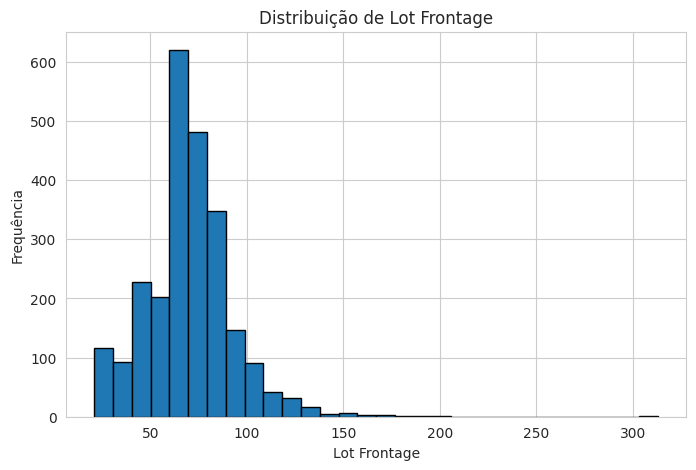


= Imputação numérica =

Coluna 'Lot Frontage' imputada com a mediana: 68.0
Coluna 'Mas Vnr Area' imputada com 0 (sem alvenaria)
Coluna 'Garage Yr Blt' imputada com 0 (sem garagem)
Coluna 'BsmtFin SF 1' imputada com 0 (sem porão)
Coluna 'BsmtFin SF 2' imputada com 0 (sem porão)
Coluna 'Bsmt Unf SF' imputada com 0 (sem porão)
Coluna 'Total Bsmt SF' imputada com 0 (sem porão)
Coluna 'Bsmt Full Bath' imputada com 0 (sem porão)
Coluna 'Bsmt Half Bath' imputada com 0 (sem porão)
Coluna 'Garage Cars' imputada com 0 (sem garagem)
Coluna 'Garage Area' imputada com 0 (sem garagem)

= Verificação Final das Colunas Imputadas =

= Valores ausentes após imputação: = 
Lot Frontage      0
Mas Vnr Area      0
BsmtFin SF 1      0
BsmtFin SF 2      0
Bsmt Unf SF       0
Total Bsmt SF     0
Bsmt Full Bath    0
Bsmt Half Bath    0
Garage Yr Blt     0
Garage Cars       0
Garage Area       0
dtype: int64


In [10]:
# 4. Investigação, justificativa e implementação da imputação numérica

print("""
Minha justificativa é...
Lot Frontage: valores ausentes por erro/omissão; distribuição assimétrica → imputado com MEDIANA (mais robusta a outliers).
Mas Vnr Area: ausência de alvenaria → imputado com 0.
Garage Yr Blt: imóvel sem garagem → imputado com 0.
Basement features (áreas e banheiros de porão): imóvel sem porão → imputado com 0.
Garage features (capacidade e área): imóvel sem garagem → imputado com 0.

Critério:
- Mediana: quando há omissão em variável contínua com outliers.
- Zero: quando NaN representa ausência real do atributo.
""")

# Selecionar colunas numéricas com valores ausentes
df_imputed2 = df_imputed.copy()
missing_numeric = df_imputed2.select_dtypes(include=['float64', 'int64']).isnull().sum()
missing_numeric = missing_numeric[missing_numeric > 0]

print("= Colunas numéricas com valores ausentes antes da imputação =\n")
print(missing_numeric)

# Analisar LotFrontage
print("\n= Descrição estatística de Lot Frontage =\n")
print(df_imputed2['Lot Frontage'].describe())

plt.figure(figsize=(8,5))
df_imputed2['Lot Frontage'].hist(bins=30, edgecolor='black')
plt.title("Distribuição de Lot Frontage")
plt.xlabel("Lot Frontage")
plt.ylabel("Frequência")
plt.show()

print("\n= Imputação numérica =\n")
# 1. Lot Frontage → distribuição assimétrica → usar mediana
if "Lot Frontage" in df_imputed2.columns:
    mediana = df_imputed2["Lot Frontage"].median()
    df_imputed2["Lot Frontage"] = df_imputed2["Lot Frontage"].fillna(mediana)
    print(f"Coluna 'Lot Frontage' imputada com a mediana: {mediana}")

# 2. Mas Vnr Area → ausência de alvenaria → 0
if "Mas Vnr Area" in df_imputed2.columns:
    df_imputed2["Mas Vnr Area"] = df_imputed2["Mas Vnr Area"].fillna(0)
    print("Coluna 'Mas Vnr Area' imputada com 0 (sem alvenaria)")

# 3. Garage Yr Blt → sem garagem → 0
if "Garage Yr Blt" in df_imputed2.columns:
    df_imputed2["Garage Yr Blt"] = df_imputed2["Garage Yr Blt"].fillna(0)
    print("Coluna 'Garage Yr Blt' imputada com 0 (sem garagem)")

# 4. Basement features → ausência de porão → 0
basement_cols = [
    "BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF",
    "Bsmt Full Bath", "Bsmt Half Bath"
]
for col in basement_cols:
    if col in df_imputed2.columns:
        df_imputed2[col] = df_imputed2[col].fillna(0)
        print(f"Coluna '{col}' imputada com 0 (sem porão)")

# 5. Garage features → ausência de garagem → 0
garage_cols = ["Garage Cars", "Garage Area"]
for col in garage_cols:
    if col in df_imputed2.columns:
        df_imputed2[col] = df_imputed2[col].fillna(0)
        print(f"Coluna '{col}' imputada com 0 (sem garagem)")


# Verificação final
missing_numeric_after = df_imputed2[missing_numeric.index].isnull().sum()
print("\n= Verificação Final das Colunas Imputadas =\n")
print(f"= Valores ausentes após imputação: = \n{missing_numeric_after}")



### Seção 3: Validação de Tipos de Dados

**Enunciado:** A forma como os dados são armazenados nem sempre reflete sua natureza real. Sua tarefa é identificar e corrigir essas discrepâncias.

1.  **Tomada de Decisão:** Inspecione as colunas com tipo de dado numérico (`int64`, `float64`). Existe alguma que, apesar de ser um número, representa uma categoria (ex: um código)? Identifique-as, explique por que tratá-las como números contínuos seria um erro para um modelo de machine learning, e converta-as para um tipo de dado mais apropriado (`object` ou `category`).

In [11]:
# Célula de resposta para a Seção 3


# 1. Identifique, justifique e converta os tipos de dados
# print("As colunas X e Y são categóricas porque...")

print("""
As colunas MS SubClass, Mo Sold e Yr Sold são categóricas, apesar de estarem numéricas, porque representam códigos/rótulos.
Tratá-las como números contínuos seria um erro, pois induziria o modelo a interpretar relações de magnitude ou distância entre os valores que não existem.

As colunas Overall Qual e Overall Cond são ordinais, não contínuas, devendo ser tratadas de forma especial.
""")

# Copiar dataset tratado
df_validated = df_imputed2.copy()

# Colunas numéricas que são categorias
categorical_from_numeric = ["MS SubClass", "Mo Sold", "Yr Sold"]

for col in categorical_from_numeric:
    if col in df_validated.columns:
        df_validated[col] = df_validated[col].astype("category")
        print(f"Coluna '{col}' convertida para category")

# Colunas ordinais (continuam numéricas, mas com interpretação especial)
ordinal_cols = ["Overall Qual", "Overall Cond"]
print(f"\nColunas {ordinal_cols} são ordinais: mantidas como numéricas, mas usadas com cautela.")



As colunas MS SubClass, Mo Sold e Yr Sold são categóricas, apesar de estarem numéricas, porque representam códigos/rótulos.
Tratá-las como números contínuos seria um erro, pois induziria o modelo a interpretar relações de magnitude ou distância entre os valores que não existem.

As colunas Overall Qual e Overall Cond são ordinais, não contínuas, devendo ser tratadas de forma especial.

Coluna 'MS SubClass' convertida para category
Coluna 'Mo Sold' convertida para category
Coluna 'Yr Sold' convertida para category

Colunas ['Overall Qual', 'Overall Cond'] são ordinais: mantidas como numéricas, mas usadas com cautela.


### Seção 4: Análise e Tratamento de Outliers

**Enunciado:** Valores extremos podem distorcer análises e prejudicar modelos. Investigue e trate os outliers de forma estratégica.

1.  Visualize a distribuição da variável alvo (`SalePrice`) e de outras features numéricas importantes, como `GrLivArea`, usando as técnicas que preferir (histogramas, box plots).
2.  Crie um gráfico de dispersão (scatter plot) para visualizar a relação entre `GrLivArea` e `SalePrice`.
3.  **Tomada de Decisão:** Com base no gráfico de dispersão, identifique visualmente as observações que parecem ser outliers problemáticos (ex: casas muito grandes com preços desproporcionalmente baixos). Defina um critério lógico para removê-los. Justifique sua escolha e implemente a remoção, explicando o impacto esperado no modelo.

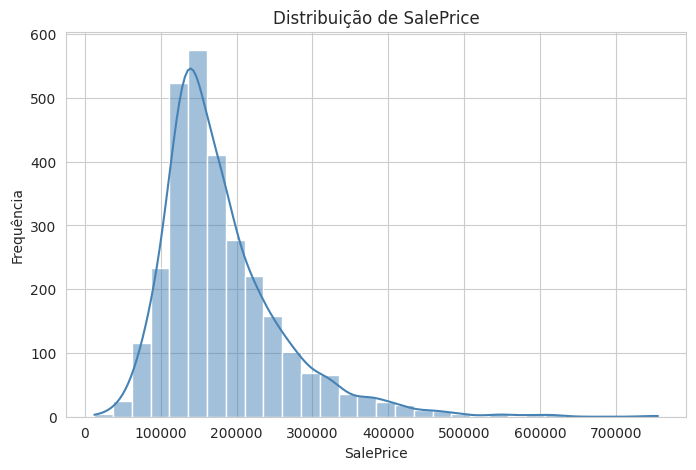

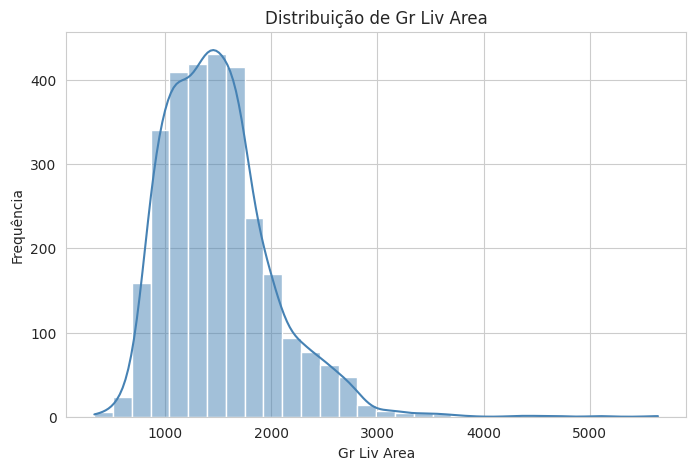

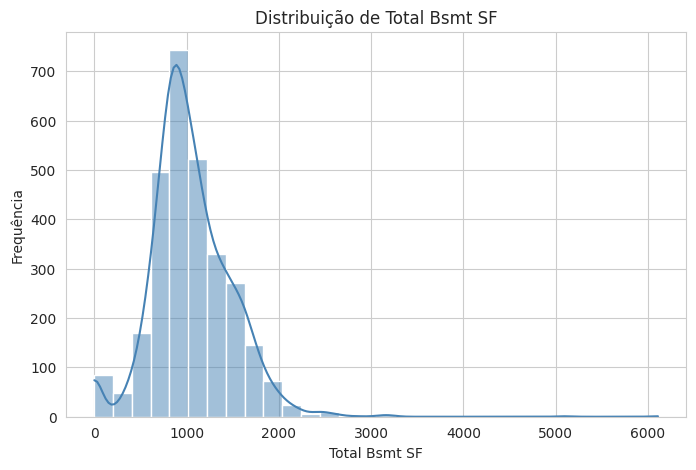

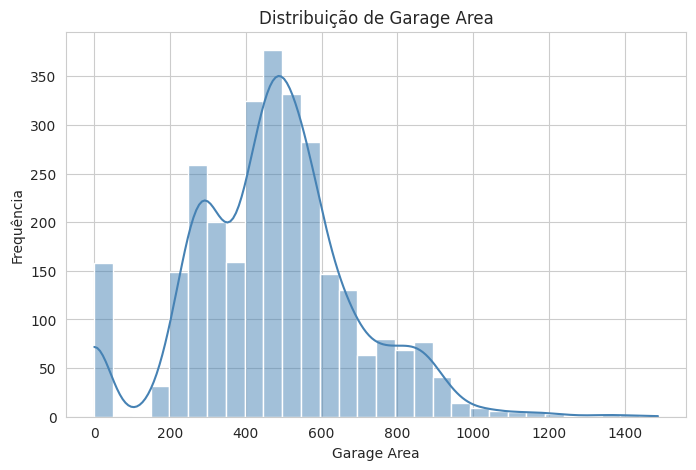

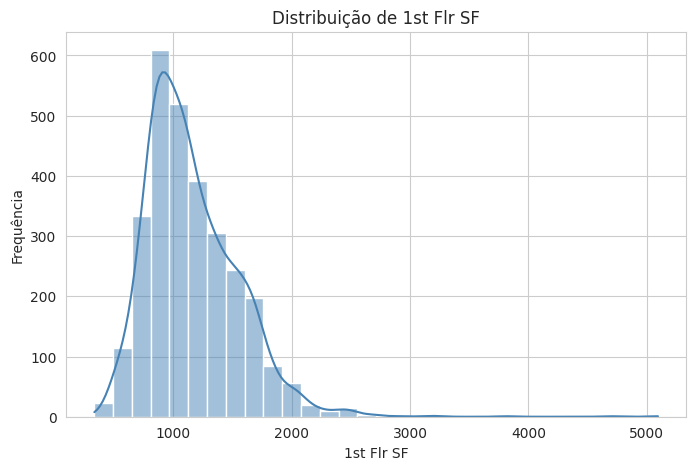

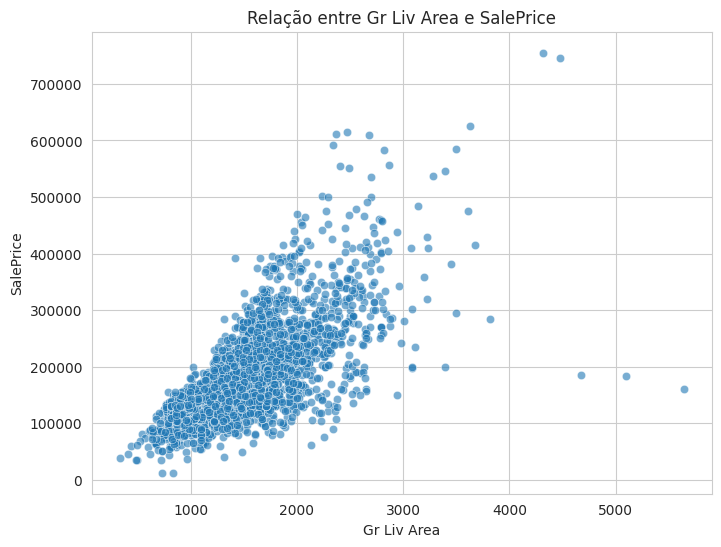

In [17]:
# Célula de resposta para a Seção 4

# 1 e 2. Visualize as distribuições e a relação entre as variáveis

# Lista de variáveis numéricas importantes para verificar
features_numericas = ["SalePrice", "Gr Liv Area", "Total Bsmt SF", "Garage Area", "1st Flr SF"]

# Plotar histogramas
for feature in features_numericas:
    plt.figure(figsize=(8,5))
    sns.histplot(df_validated[feature], kde=True, bins=30, color="steelblue")
    plt.title(f"Distribuição de {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequência")
    plt.show()

# Scatter plot entre GrLivArea e SalePrice
plt.figure(figsize=(8,6))
sns.scatterplot(x=df_validated["Gr Liv Area"], y=df_validated["SalePrice"], alpha=0.6)
plt.title("Relação entre Gr Liv Area e SalePrice")
plt.xlabel("Gr Liv Area")
plt.ylabel("SalePrice")
plt.show()




-Identificação visual: no gráfico, observa-se que a maioria dos imóveis acima de ~4000 pés² tem preços na faixa de ~200.000–300.000 dólares, 
valores anormalmente baixos para casas tão grandes.

-Critério lógico: remover casas com Gr Liv Area > 4000 e SalePrice < 300000.

-Justificativa:
Essas casas não seguem o padrão de mercado.
Podem ser erros de registro ou propriedades atípicas que não representam o comportamento da maioria.
Mantê-las prejudicaria o ajuste do modelo (afetando média, variância e coeficientes).

-Impacto esperado:
Melhor alinhamento entre variáveis.
Redução da influência desproporcional de poucos pontos extremos.
Modelos mais robustos e com melhor generalização.

Formato original: (2930, 78)
Número de outliers identificados: 3
Formato após remoção: (2927, 78)


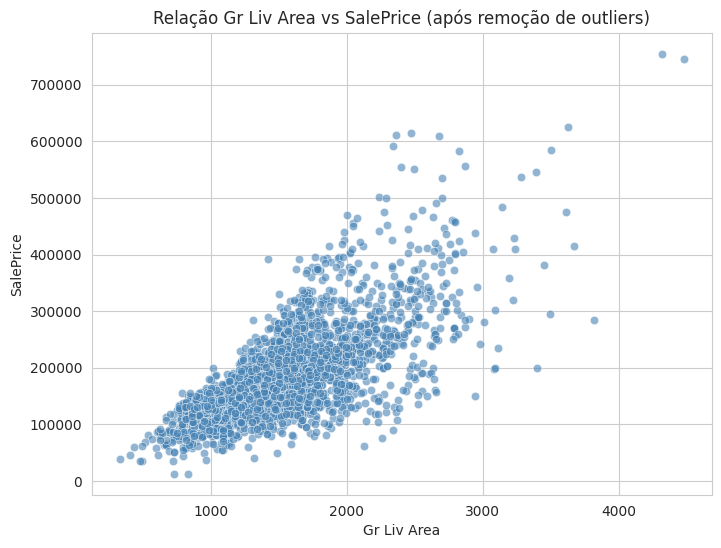

In [19]:
# 3. Defina seu critério, justifique e remova os outliers
# print("Meu critério para remoção é..., porque...")
# Lembre-se de resetar o índice do DataFrame após a remoção

# Justificativa
print("""
-Identificação visual: no gráfico, observa-se que a maioria dos imóveis acima de ~4000 pés² tem preços na faixa de ~200.000–300.000 dólares,
valores anormalmente baixos para casas tão grandes.

-Critério lógico: remover casas com Gr Liv Area > 4000 e SalePrice < 300000.

-Justificativa:
Essas casas não seguem o padrão de mercado.
Podem ser erros de registro ou propriedades atípicas que não representam o comportamento da maioria.
Mantê-las prejudicaria o ajuste do modelo (afetando média, variância e coeficientes).

-Impacto esperado:
Melhor alinhamento entre variáveis.
Redução da influência desproporcional de poucos pontos extremos.
Modelos mais robustos e com melhor generalização.
""")

# Antes da remoção
print(f"Formato original: {df_validated.shape}")

# Critério para remoção de outliers
outlier_condition = (df_validated["Gr Liv Area"] > 4000) & (df_validated["SalePrice"] < 300000)

# Quantos outliers atendem ao critério
n_outliers = df_validated[outlier_condition].shape[0]
print(f"Número de outliers identificados: {n_outliers}")

# Remover e resetar índice
df_outlier_removed = df_validated[~outlier_condition].reset_index(drop=True)

# Após a remoção
print(f"Formato após remoção: {df_outlier_removed.shape}")

# Scatter plot atualizado
plt.figure(figsize=(8,6))
sns.scatterplot(x=df_outlier_removed["Gr Liv Area"], y=df_outlier_removed["SalePrice"], alpha=0.6, color="steelblue")
plt.title("Relação Gr Liv Area vs SalePrice (após remoção de outliers)")
plt.xlabel("Gr Liv Area")
plt.ylabel("SalePrice")
plt.show()


### Seção 5: Engenharia de Features (Feature Engineering)

**Enunciado:** A criação de novas features é uma das etapas mais criativas e impactantes. Pense em como as features existentes podem ser combinadas ou transformadas para criar novas informações.

1.  **Tomada de Decisão:** Proponha e implemente a criação de pelo menos **três** novas features que você acredita que possam ser úteis para prever o preço de uma casa. Explique o raciocínio por trás de cada uma.
    * *Sugestões (sinta-se livre para criar outras):* Qual a idade da casa na data da venda? Qual a área total da casa somando todos os andares e porão? A casa foi reformada desde que foi construída?

In [25]:
# Célula de resposta para a Seção 5


# Cópia do dataset sem outliers
df_features = df_outlier_removed.copy()

# Feature 1: Área total da casa

print("Criei a feature 'Total_Area' porque o preço está fortemente associado ao espaço total disponível.")
print("Somando a área acima do solo (Gr Liv Area), o porão (Total Bsmt SF) e a garagem (Garage Area), temos uma medida mais completa do tamanho útil do imóvel.\n")

df_features["Total_Area"] = (
    df_features["Gr Liv Area"] +
    df_features["Total Bsmt SF"] +
    df_features["Garage Area"]
)


# Feature 2: Total de comodos

print("Criei a feature 'TotalRooms_All' porque ela representa o número total de cômodos de uma casa.")
print("Inclui dormitórios, cozinhas, salas, banheiros completos e de meio, tanto acima do solo quanto no porão.\n")

df_features["TotalRooms_All"] = (
    df_features["TotRms AbvGrd"] +
    df_features["Bedroom AbvGr"] +
    df_features["Kitchen AbvGr"] +
    df_features["Full Bath"] +
    df_features["Half Bath"] +
    df_features["Bsmt Full Bath"] +
    df_features["Bsmt Half Bath"]
)


# Feature 3: Relação área do lote vs área construída (Lot_Utilization)

print("Criei a feature 'Lot_Utilization' porque ela mostra a proporção do lote que é ocupada pela área habitável.")
print("Casas que utilizam melhor o espaço do lote podem ter valorização maior.\n")

df_features["Lot_Utilization"] = df_features["Gr Liv Area"] / df_features["Lot Area"]

print("= Verificação rápida =")

print("\n= Amostra das novas features =\n")
print(df_features[["Gr Liv Area", "Total Bsmt SF", "Garage Area", "Total_Area",
                   "TotRms AbvGrd", "Bedroom AbvGr", "Kitchen AbvGr", "Full Bath", "Half Bath", "Bsmt Full Bath", "Bsmt Half Bath","TotalRooms_All",
                   "Lot Area", "Gr Liv Area", "Lot_Utilization"]].head())


Criei a feature 'Total_Area' porque o preço está fortemente associado ao espaço total disponível.
Somando a área acima do solo (Gr Liv Area), o porão (Total Bsmt SF) e a garagem (Garage Area), temos uma medida mais completa do tamanho útil do imóvel.

Criei a feature 'TotalRooms_All' porque ela representa o número total de cômodos de uma casa.
Inclui dormitórios, cozinhas, salas, banheiros completos e de meio, tanto acima do solo quanto no porão.

Criei a feature 'Lot_Utilization' porque ela mostra a proporção do lote que é ocupada pela área habitável.
Casas que utilizam melhor o espaço do lote podem ter valorização maior.

= Verificação rápida =

= Amostra das novas features =

   Gr Liv Area  Total Bsmt SF  Garage Area  Total_Area  TotRms AbvGrd  \
0         1656         1080.0        528.0      3264.0              7   
1          896          882.0        730.0      2508.0              5   
2         1329         1329.0        312.0      2970.0              6   
3         2110      

### Seção 6: Codificação de Variáveis Categóricas

**Enunciado:** Para que o dataset possa ser usado por um modelo, todas as features precisam ser numéricas.

1.  **Tomada de Decisão:** Identifique as colunas categóricas (`object`) restantes. Qual é a estratégia de codificação mais adequada (One-Hot Encoding, Label Encoding, etc.)? Lembre-se de considerar se os dados são nominais ou ordinais e o impacto de cada técnica. Justifique sua escolha geral e implemente a codificação para transformar todas as features restantes em formato numérico.

In [29]:
# Célula de resposta para a Seção 6

# Justifique sua escolha de método de codificação
# print("Escolhi o método X porque...")

# Implemente a codificação

# Identificar colunas categóricas restantes
categorical_cols = df_features.select_dtypes(include=["object", "category"]).columns.tolist()

print("= Colunas categóricas identificadas =")
print(categorical_cols)

# Justificativa da escolha
print("""
Escolhi usar One-Hot Encoding (dummies) para variáveis nominais (sem ordem natural, como 'Bairro', 'Material de revestimento', 'Tipo de garagem').
Isso evita que o modelo interprete uma ordem ou magnitude inexistente entre categorias.

Escolhi Label Encoding apenas se tivermos variáveis ordinais explícitas, mas no nosso caso já tratamos 'Overall Qual' e 'Overall Cond' como numéricas ordinais.

Portanto, a estratégia geral é:
- Variáveis nominais → One-Hot Encoding.
- Variáveis ordinais → já mantidas como inteiras, sem codificação adicional.
""")

# Implementação com pandas.get_dummies (One-Hot Encoding)
df_encoded = pd.get_dummies(df_features, columns=categorical_cols, drop_first=True)

# Converter colunas booleanas para inteiros (0/1)
bool_cols = df_encoded.select_dtypes(include=["bool"]).columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

print("= Transformação realizada =")
print(f"Formato original: {df_features.shape}")
print(f"Formato após codificação: {df_encoded.shape}")
print(f"Número de novas colunas criadas: {df_encoded.shape[1] - df_features.shape[1]}")

= Colunas categóricas identificadas =
['MS SubClass', 'MS Zoning', 'Street', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC', 'Central Air', 'Electrical', 'Kitchen Qual', 'Functional', 'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond', 'Paved Drive', 'Mo Sold', 'Yr Sold', 'Sale Type', 'Sale Condition']

Escolhi usar One-Hot Encoding (dummies) para variáveis nominais (sem ordem natural, como 'Bairro', 'Material de revestimento', 'Tipo de garagem').
Isso evita que o modelo interprete uma ordem ou magnitude inexistente entre categorias.

Escolhi Label Encoding apenas se tivermos variáveis ordinais explícitas, mas no nosso caso já tratamos 'Overall Qual

### Seção 7: Verificação Final

**Enunciado:** Antes de entregar o trabalho, faça uma verificação final para garantir que o DataFrame está impecável.

1.  Verifique se ainda existe algum valor ausente no DataFrame.
2.  Verifique os tipos de dados de todas as colunas. Todos devem ser numéricos (`int` ou `float`).
3.  Exiba as dimensões do seu DataFrame final. Compare com as dimensões originais e comente brevemente as mudanças.

In [31]:
# Célula de resposta para a Seção 7

# Seção 7: Verificação Final

print("===== Verificação Final =====\n")

# 1. Verificar valores ausentes
missing_final = df_encoded.isnull().sum().sum()
print(f"Total de valores ausentes no DataFrame final: {missing_final}")

if missing_final == 0:
    print("Não há valores ausentes no DataFrame final.\n")
else:
    print("Ainda existem valores ausentes! Verifique novamente.\n")

# 2. Verificar tipos de dados
print("===== Tipos de Dados =====\n")
print(df_encoded.dtypes.value_counts())
print("\nTodos os tipos devem ser numéricos (int64/float64).")

# 3. Verificar dimensões finais
print("\n===== Dimensões =====\n")
print(f"Formato original: {df.shape}")
print(f"Após remoção de colunas/imputação/outliers/features: {df_features.shape}")
print(f"Após codificação final: {df_encoded.shape}")

print("""
= Comentário =
O dataset original tinha menos colunas, mas várias foram removidas (colunas com >80% de valores ausentes),
enquanto outras foram expandidas pelo One-Hot Encoding.
Também houve aumento no número de colunas pelas novas features criadas (Total_Area, TotalRooms_All, Lot_Utilization).
Portanto, o número de linhas diminuiu (remoção de outliers), mas o número de colunas aumentou bastante (codificação + novas variáveis).
""")

# 4. Informações completas do dataset final
print("\n===== Informações do DataFrame Final =====\n")
df_encoded.info()


===== Verificação Final =====

Total de valores ausentes no DataFrame final: 0
Não há valores ausentes no DataFrame final.

===== Tipos de Dados =====

int64      278
float64     14
Name: count, dtype: int64

Todos os tipos devem ser numéricos (int64/float64).

===== Dimensões =====

Formato original: (2930, 82)
Após remoção de colunas/imputação/outliers/features: (2927, 81)
Após codificação final: (2927, 292)

= Comentário =
O dataset original tinha menos colunas, mas várias foram removidas (colunas com >80% de valores ausentes),
enquanto outras foram expandidas pelo One-Hot Encoding.
Também houve aumento no número de colunas pelas novas features criadas (Total_Area, TotalRooms_All, Lot_Utilization).
Portanto, o número de linhas diminuiu (remoção de outliers), mas o número de colunas aumentou bastante (codificação + novas variáveis).


===== Informações do DataFrame Final =====

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2927 entries, 0 to 2926
Columns: 292 entries, Order to Sa